# 15. Robustez, interpretabilidad, errores y techo de desempeño

En este capítulo evaluamos cómo se degradan los modelos ante perturbaciones de la imagen y ante un cambio de fondo, dónde se fija su atención, en qué imágenes fallan y cuánto margen de mejora real queda. Cerramos con la ablación del mejor modelo. Las perturbaciones, el Grad-CAM y la fracción de atención sobre el fondo están en el preregistro; el resto de los análisis es exploratorio.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "entregable2" / "src").exists())
E2 = ROOT / "entregable2"
for p in (E2 / "analisis", E2):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats as st
from IPython.display import display
import figuras as FG
from comun import MODELS, E2_MODELS, SEEDS, CLASSES, aligned, fast_f1_macro
FG.setup()
pd.set_option("display.precision", 3)
SUM = E2 / "results" / "summary"; COMP = E2 / "results" / "complementario"
orden = pd.read_csv(SUM / "f1_macro_por_semilla.csv")[MODELS].mean().sort_values(ascending=False).index.tolist()

## 15.1 Robustez ante perturbaciones y cambio de fondo

Las perturbaciones son las del capítulo 5 y se aplican a la imagen normalizada de prueba con la semilla 2026:

- ruido gaussiano con $\sigma = 0.05$ y $0.10$;
- desenfoque gaussiano;
- brillo de −30 % y +30 %;
- oclusión con un cuadrado gris;
- sustitución del fondo blanco por texturas (cambio de distribución emulado).

Con la imagen original, el ruido y el brillo tienen tres niveles de severidad. El desenfoque, la oclusión y el fondo tienen un nivel; el enunciado pide al menos tres por perturbación y lo declaramos como limitación.

El índice de robustez es el área bajo la curva de degradación normalizada por el F1 sin perturbar. En el ruido, $\text{IR} = \frac{1}{0.10\,F_0}\int_0^{0.10} F(\sigma)\,d\sigma$ por la regla del trapecio; vale 1 si el modelo no se degrada.

In [2]:
rb = pd.concat([pd.read_csv(SUM / "robustez.csv"), pd.read_csv(SUM / "robustez_modelos_base.csv")])
tab = rb.groupby(["model", "perturbacion"]).f1_macro.mean().unstack()
cols = ["limpio", "ruido_0.05", "ruido_0.10", "desenfoque", "brillo_-30", "brillo_+30", "oclusion", "fondo_sustituido"]
ri = pd.read_csv(COMP / "robustez_indice.csv").groupby("model")[["ir_ruido", "ir_brillo", "ir_global"]].mean()
display(tab.loc[orden, cols].join(ri).round(3))

,limpio,ruido_0.05,ruido_0.10,desenfoque,brillo_-30,brillo_+30,oclusion,fondo_sustituido,ir_ruido,ir_brillo,ir_global
model,,,,,,,,,,,
RWCNet,0.945,0.648,0.382,0.805,0.938,0.932,0.931,0.901,0.694,0.995,0.837
ViT-B16,0.938,0.894,0.837,0.871,0.929,0.928,0.932,0.919,0.950,0.995,0.961
GFN,0.921,0.797,0.559,0.764,0.921,0.911,0.919,0.894,0.834,0.997,0.894
Celik-HC,0.914,0.255,0.125,0.740,0.906,0.893,0.896,0.877,0.424,0.992,0.734
ResMsCapsule,0.899,0.419,0.166,0.543,0.883,0.880,0.859,0.822,0.529,0.990,0.726
ResNet-18,0.863,0.394,0.116,0.608,0.753,0.810,0.822,0.606,0.512,0.953,0.681
MbXception,0.861,0.222,0.103,0.589,0.785,0.800,0.832,0.630,0.409,0.960,0.657
CNN,0.826,0.185,0.132,0.360,0.720,0.741,0.781,0.568,0.402,0.942,0.603
FocusRCNet,0.811,0.145,0.073,0.502,0.699,0.740,0.779,0.635,0.362,0.943,0.629


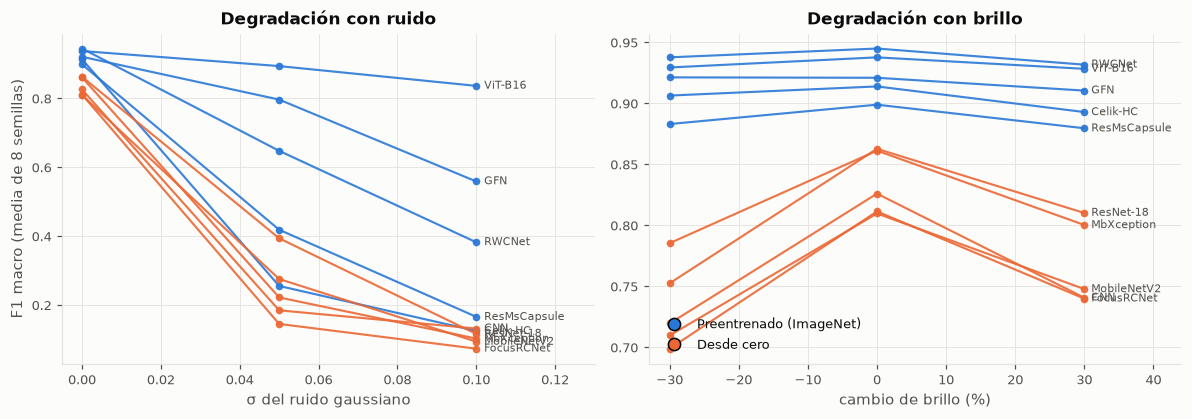

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for m in orden:
    c = FG.color_regimen(m)
    y = tab.loc[m, ["limpio", "ruido_0.05", "ruido_0.10"]].to_numpy()
    axes[0].plot([0, 0.05, 0.10], y, "o-", color=c, lw=1.4, ms=4, alpha=0.9)
    axes[0].text(0.102, y[-1], m, fontsize=7.2, va="center", color=FG.INK2)
    yb = tab.loc[m, ["brillo_-30", "limpio", "brillo_+30"]].to_numpy()
    axes[1].plot([-30, 0, 30], yb, "o-", color=c, lw=1.4, ms=4, alpha=0.9)
    axes[1].text(31, yb[-1], m, fontsize=7.2, va="center", color=FG.INK2)
axes[0].set_xlim(-0.005, 0.13); axes[0].set_xlabel("σ del ruido gaussiano"); axes[0].set_ylabel("F1 macro (media de 8 semillas)")
axes[1].set_xlim(-33, 44); axes[1].set_xlabel("cambio de brillo (%)")
axes[0].set_title("Degradación con ruido"); axes[1].set_title("Degradación con brillo")
FG.leyenda_regimen(axes[1], loc="lower left"); plt.tight_layout(); plt.show()

Ante perturbaciones distintas, los modelos responden de forma muy distinta:

- **Ruido:** es la perturbación más dañina, y separa a los modelos con atención global de las arquitecturas convolucionales. ViT-B16 conserva el 95 % de su F1 con $\sigma = 0.05$ (índice de robustez de 0.95), GFN el 87 % (0.83) y RWCNet el 69 % (0.69). Celik-HC, MbXception y FocusRCNet caen por debajo de 0.26. La sección 12.4 cuantifica esta fragilidad con IC por grupo.
- **Brillo y oclusión:** los modelos preentrenados apenas se degradan (≤ 0.04 de F1), y los entrenados desde cero pierden entre 0.03 y 0.11, como en el capítulo 5.
- **Fondo sustituido:** emula un cambio de distribución hacia condiciones de planta. Los preentrenados pierden 0.02 a 0.08 de F1 y los entrenados desde cero 0.18 a 0.26. El preentrenamiento reduce la dependencia del fondo blanco.

In [4]:
ci = pd.read_csv(COMP / "robustez_caidas_ic.csv")
display(ci.pivot(index="model", columns="perturbacion", values="caida_f1").loc[[m for m in orden if m in ci.model.unique()]].round(3))

perturbacion,desenfoque,fondo_sustituido,ruido_0.05,ruido_0.10
model,,,,
RWCNet,0.140,0.044,0.297,0.563
ViT-B16,0.067,0.019,0.044,0.101
GFN,0.157,0.027,0.124,0.362
Celik-HC,0.174,0.037,0.659,0.789
ResMsCapsule,0.356,0.077,0.480,0.733
MbXception,0.272,0.232,0.639,0.759
FocusRCNet,0.309,0.177,0.666,0.738


## 15.2 Interpretabilidad: Grad-CAM, fondo y estabilidad entre semillas

El Grad-CAM pondera los mapas de la última capa convolucional (o la normalización previa del último bloque, en los Transformers) por el gradiente de la clase verdadera. Lo calculamos sobre 10 imágenes de prueba por clase, las mismas en todas las semillas. Medimos dos cosas:

- **Fracción de la energía del mapa sobre el fondo:** compara cuánta energía cae en los píxeles de fondo, detectados por umbral de brillo, con la fracción del área que ocupa el fondo.
- **Estabilidad entre semillas:** correlación de Spearman entre los mapas de la misma imagen en cada par de semillas, y solapamiento (IoU) del 20 % de píxeles con mayor activación.

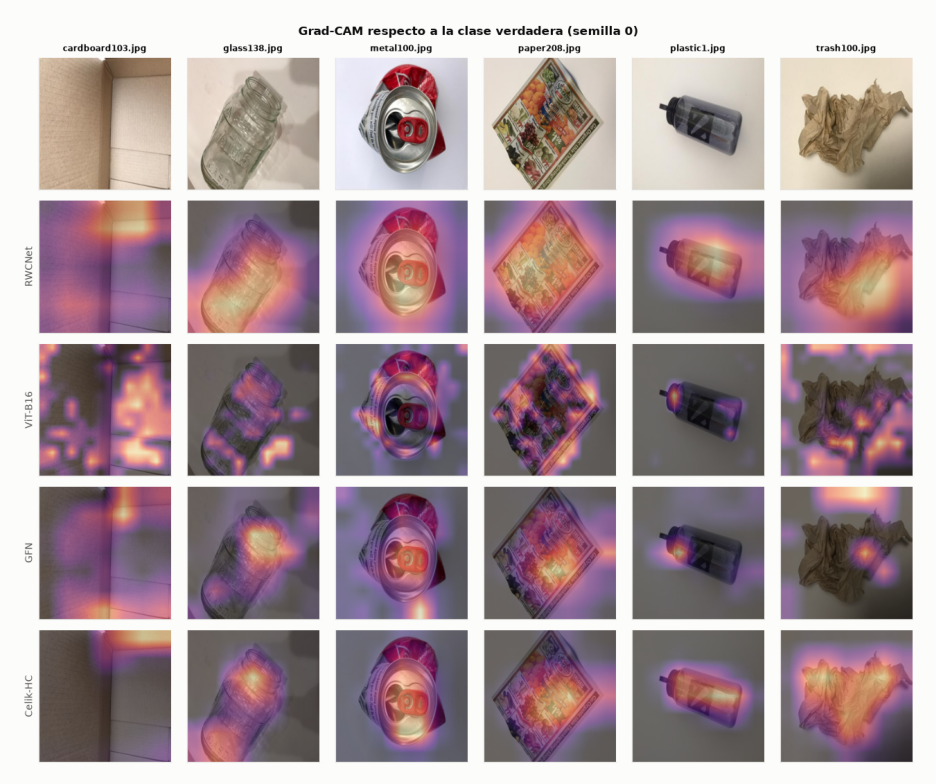

In [5]:
fig, ax = plt.subplots(figsize=(11, 9))
ax.imshow(Image.open(COMP / "figura_gradcam_ejemplos.png")); ax.axis("off"); plt.show()

In [6]:
gf = pd.read_csv(SUM / "gradcam_fondo.csv").groupby("model").agg(energia_fondo=("frac_energia_fondo", "mean"),
                                                                  area_fondo=("frac_area_fondo", "mean"), exceso=("exceso_fondo", "mean"))
ge = pd.read_csv(COMP / "gradcam_estabilidad.csv").groupby("model").agg(spearman=("spearman_medio", "mean"),
                                                                        iou_top20=("iou_top20_medio", "mean"))
display(gf.join(ge).loc[[m for m in orden if m in gf.index]].round(3))

,energia_fondo,area_fondo,exceso,spearman,iou_top20
model,,,,,
RWCNet,0.126,0.188,-0.062,0.810,0.537
ViT-B16,0.176,0.188,-0.013,0.155,0.217
GFN,0.117,0.188,-0.071,0.381,0.329
Celik-HC,0.094,0.188,-0.094,0.690,0.513
ResMsCapsule,0.114,0.188,-0.074,0.475,0.363
MbXception,0.129,0.188,-0.060,0.755,0.514
FocusRCNet,0.136,0.188,-0.053,0.550,0.377


**Coherencia con el dominio.** Todos los modelos concentran la atención en el objeto: la fracción de energía sobre el fondo (9 % a 18 %) es menor que la del área de fondo (19 %). Las CNN preentrenadas (RWCNet, Celik-HC y GFN) producen mapas compactos sobre el objeto y su contorno. ViT-B16 produce mapas más dispersos (18 % de energía en el fondo) que, aun así, siguen al objeto en los ejemplos.

**Estabilidad.** La correlación de los mapas entre semillas separa dos grupos:

- **Mapas estables:** RWCNet ($\rho = 0.81$), MbXception (0.76) y Celik-HC (0.69). Sus explicaciones dependen poco de la semilla y se pueden interpretar.
- **Estabilidad intermedia:** FocusRCNet (0.55), ResMsCapsule (0.48) y GFN (0.38).
- **ViT-B16:** el menos estable ($\rho = 0.16$; IoU del 20 % superior de 0.22), a pesar de que sus predicciones son estables. Sus explicaciones por imagen no son evidencia sólida de qué región usa el modelo.

**Fidelidad.** No ejecutamos la prueba de borrado o inserción, que requiere los pesos de cada corrida. Las corridas de Colab no conservaron los pesos de ViT-B16, GFN y Celik-HC, y la declaramos como limitación.

## 15.3 Análisis de errores

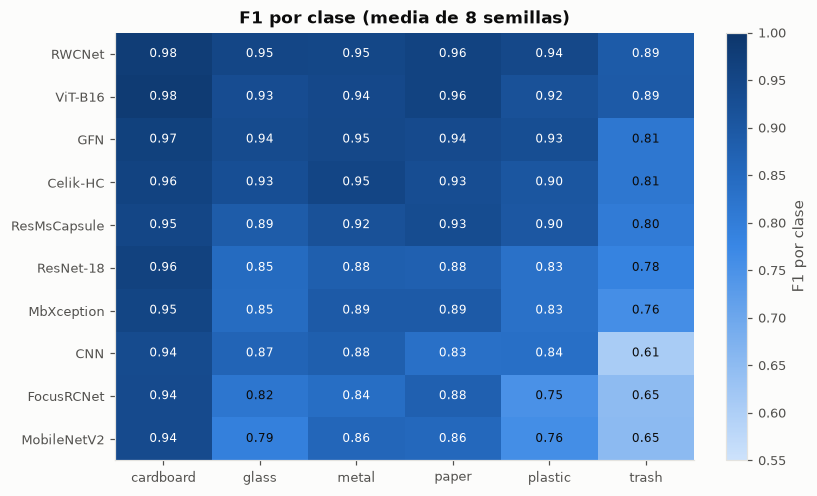

In [7]:
fc = pd.read_csv(SUM / "f1_por_clase.csv")
fcb = []
from comun import run_dir, load_pickle
for m in ["CNN", "MobileNetV2", "ResNet-18"]:
    for s in SEEDS:
        mt = load_pickle(run_dir(m, s) / "metrics_test.pkl")
        for c in CLASSES:
            fcb.append({"model": m, "seed": s, "clase": c, "f1": mt["f1_per_class"][c]})
fc = pd.concat([fc, pd.DataFrame(fcb)])
hm = fc.groupby(["model", "clase"]).f1.mean().unstack().loc[orden, CLASSES]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("seq", FG.SEQ)
im = ax.imshow(hm.to_numpy(), cmap=cmap, vmin=0.55, vmax=1.0, aspect="auto")
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = hm.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.82 else FG.INK)
ax.set_xticks(range(6), CLASSES); ax.set_yticks(range(len(orden)), orden); ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.04, label="F1 por clase")
ax.set_title("F1 por clase (media de 8 semillas)"); plt.tight_layout(); plt.show()

**Desempeño por clase.**

- **`trash`:** la clase más difícil en los diez modelos (F1 entre 0.61 y 0.89), con solo 19 imágenes de prueba.
- **`plastic` y `glass`:** las siguientes en dificultad, por las confusiones entre materiales transparentes.
- **`cardboard`:** la más fácil en todos los modelos (0.94 a 0.98).

La ventaja de los mejores modelos sobre el de referencia se concentra en `trash`, `plastic` y `glass`, las clases donde el preentrenamiento aporta rasgos de material que no se aprenden con unas 2500 imágenes.

In [8]:
ec = pd.read_csv(COMP / "errores_compartidos.csv")
M = pd.DataFrame(np.eye(len(MODELS)), index=MODELS, columns=MODELS)
for r in ec.itertuples():
    M.loc[r.A, r.B] = M.loc[r.B, r.A] = r.corr_errores
display(M.loc[orden, orden].round(2))
ens = pd.read_csv(COMP / "ensambles.csv").groupby("ensamble").f1_macro.agg(["mean", "std"])
display(ens.round(4))
ei = pd.read_csv(COMP / "errores_por_imagen.csv")
print(f"Imágenes que fallan al menos la mitad de las 80 corridas: {(ei.tasa_error_80 >= 0.5).sum()}; "
      f"al menos el 75 %: {(ei.tasa_error_80 >= 0.75).sum()}; ninguna corrida: {(ei.tasa_error_80 == 0).sum()} de 361")

,RWCNet,ViT-B16,GFN,Celik-HC,ResMsCapsule,ResNet-18,MbXception,CNN,FocusRCNet,MobileNetV2
RWCNet,1.00,0.41,0.51,0.45,0.44,0.32,0.33,0.32,0.29,0.31
ViT-B16,0.41,1.00,0.40,0.36,0.31,0.25,0.25,0.26,0.26,0.27
GFN,0.51,0.40,1.00,0.47,0.36,0.32,0.28,0.27,0.30,0.30
Celik-HC,0.45,0.36,0.47,1.00,0.39,0.28,0.28,0.29,0.33,0.34
ResMsCapsule,0.44,0.31,0.36,0.39,1.00,0.37,0.31,0.31,0.30,0.33
ResNet-18,0.32,0.25,0.32,0.28,0.37,1.00,0.58,0.43,0.49,0.51
MbXception,0.33,0.25,0.28,0.28,0.31,0.58,1.00,0.39,0.52,0.51
CNN,0.32,0.26,0.27,0.29,0.31,0.43,0.39,1.00,0.37,0.38
FocusRCNet,0.29,0.26,0.30,0.33,0.30,0.49,0.52,0.37,1.00,0.51
MobileNetV2,0.31,0.27,0.30,0.34,0.33,0.51,0.51,0.38,0.51,1.00


,mean,std
ensamble,,
10 modelos,0.943,0.004
RWCNet+ViT-B16+GFN,0.951,0.009
oráculo (alguno acierta),0.991,0.004


Imágenes que fallan al menos la mitad de las 80 corridas: 23; al menos el 75 %: 7; ninguna corrida: 165 de 361


**Errores compartidos y complementariedad.**

- **Correlación de errores:** la correlación entre los indicadores de error de dos modelos en la misma semilla va de 0.25 a 0.58. Es mayor entre los modelos entrenados desde cero (0.58 entre MbXception y ResNet-18) y menor entre ViT-B16 y las CNN (alrededor de 0.25): el Transformer se equivoca en imágenes distintas.
- **Ensambles:** promediar las probabilidades de RWCNet, ViT-B16 y GFN da un F1 de 0.951, apenas superior al de RWCNet solo (0.945). El ensamble de los diez modelos (0.943) no lo mejora. Un oráculo que acierta si algún modelo acierta llega a 0.99 de accuracy: hay complementariedad, pero el voto no la aprovecha.
- **Imágenes difíciles:** 23 imágenes fallan en al menos la mitad de las 80 corridas y solo 7 en al menos el 75 %. La dificultad se concentra en pocos casos.

**Taxonomía de los casos difíciles.** Definimos cinco categorías mutuamente excluyentes y clasificamos por inspección visual las 23 imágenes que fallan en al menos la mitad de las corridas:

- (a) posible error de etiqueta;
- (b) material mixto o compuesto;
- (c) transparencia o reflejo que confunde plástico, vidrio y metal;
- (d) encuadre, fondo o escena atípicos;
- (e) otro.

La muestra es menor que los 100 casos por modelo que sugiere el enunciado, porque los modelos fallan pocas imágenes de forma sistemática.

,casos,proporción,IC 95 % (Wilson)
categoría,,,
transparencia o reflejo,9,0.391,"[0.22, 0.59]"
material mixto o compuesto,7,0.304,"[0.16, 0.51]"
"encuadre, fondo o escena atípicos",5,0.217,"[0.10, 0.42]"
posible error de etiqueta,1,0.043,"[0.01, 0.21]"
otro,1,0.043,"[0.01, 0.21]"


,relpath,clase,consenso,tasa_error_80,categoría
0,plastic/plastic455.jpg,plastic,paper,1.000,material mixto o compuesto
1,glass/glass186.jpg,glass,metal,1.000,posible error de etiqueta
2,glass/glass278.jpg,glass,paper,0.938,"encuadre, fondo o escena atípicos"
3,plastic/plastic456.jpg,plastic,metal,0.925,material mixto o compuesto
4,plastic/plastic457.jpg,plastic,glass,0.887,material mixto o compuesto
5,trash/trash91.jpg,trash,paper,0.838,material mixto o compuesto
6,paper/paper594.jpg,paper,trash,0.762,"encuadre, fondo o escena atípicos"
7,plastic/plastic303.jpg,plastic,glass,0.700,transparencia o reflejo
8,cardboard/cardboard279.jpg,cardboard,paper,0.700,"encuadre, fondo o escena atípicos"
9,metal/metal37.jpg,metal,glass,0.700,transparencia o reflejo


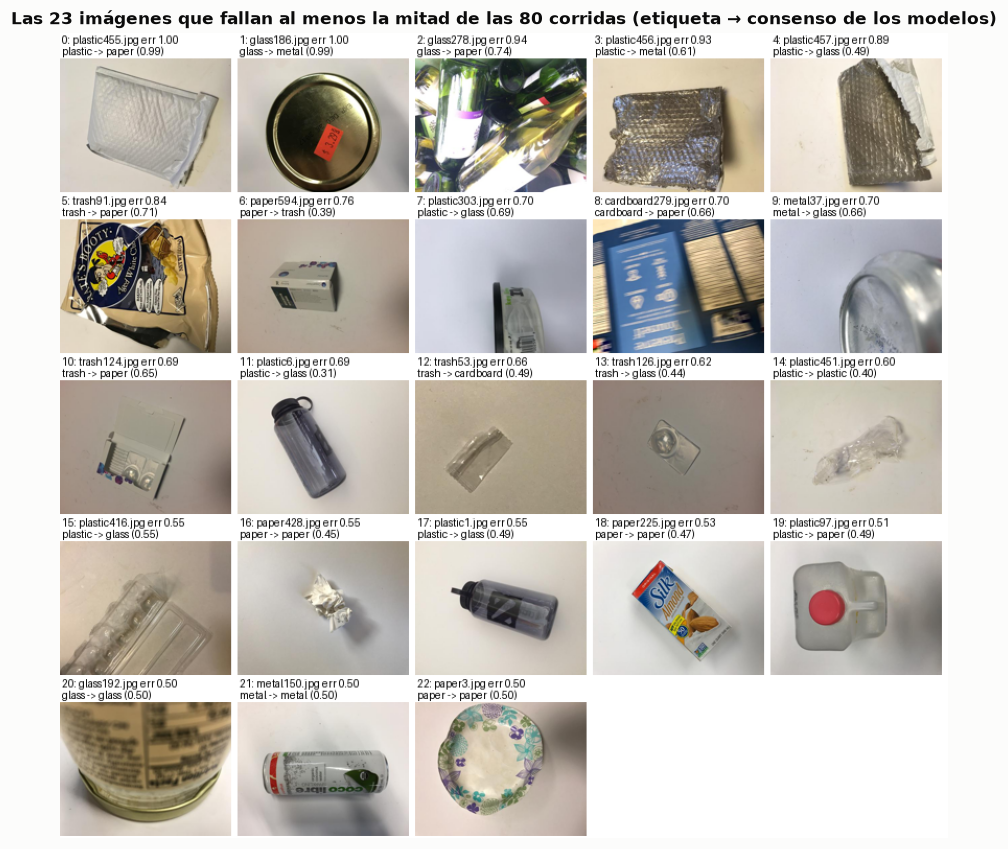

In [9]:
tax = {"plastic/plastic455.jpg": "b", "glass/glass186.jpg": "a", "glass/glass278.jpg": "d", "plastic/plastic456.jpg": "b",
       "plastic/plastic457.jpg": "b", "trash/trash91.jpg": "b", "paper/paper594.jpg": "d", "plastic/plastic303.jpg": "c",
       "cardboard/cardboard279.jpg": "d", "metal/metal37.jpg": "c", "trash/trash124.jpg": "b", "plastic/plastic6.jpg": "c",
       "trash/trash53.jpg": "c", "trash/trash126.jpg": "c", "plastic/plastic451.jpg": "c", "plastic/plastic416.jpg": "c",
       "paper/paper428.jpg": "d", "plastic/plastic1.jpg": "c", "paper/paper225.jpg": "b", "plastic/plastic97.jpg": "c",
       "glass/glass192.jpg": "d", "metal/metal150.jpg": "e", "paper/paper3.jpg": "b"}
nombres = {"a": "posible error de etiqueta", "b": "material mixto o compuesto", "c": "transparencia o reflejo",
           "d": "encuadre, fondo o escena atípicos", "e": "otro"}
dif = ei[ei.tasa_error_80 >= 0.5].copy(); dif["categoría"] = dif.relpath.map(tax).map(nombres)
cnt = dif["categoría"].value_counts()
n = len(dif)
res = pd.DataFrame({"casos": cnt, "proporción": cnt / n})
res["IC 95 % (Wilson)"] = [f"[{l:.2f}, {h:.2f}]" for l, h in
                            [st.binomtest(int(k), n).proportion_ci(method="wilson") for k in cnt]]
display(res)
display(dif[["relpath", "clase", "consenso", "tasa_error_80", "categoría"]].reset_index(drop=True))
fig, ax = plt.subplots(figsize=(11, 9.5))
ax.imshow(Image.open(COMP / "_imagenes_dificiles.png")); ax.axis("off")
ax.set_title("Las 23 imágenes que fallan al menos la mitad de las 80 corridas (etiqueta → consenso de los modelos)")
plt.show()

Las categorías dominantes son la transparencia o el reflejo (9 de 23) y el material mixto (7 de 23):

- **Transparencia o reflejo:** botellas de plástico translúcido clasificadas como vidrio, o una lata reflectante clasificada como vidrio.
- **Material mixto:** un sobre de burbujas con papel, empaques laminados con aluminio, un tetrapak.

Ambos son errores de ambigüedad del material en una fotografía RGB, no de la arquitectura. Solo un caso (`glass186`, una tapa metálica etiquetada como vidrio) es un error de etiqueta probable. Las clasificaciones son una revisión visual de los autores con apoyo de IA, y no una auditoría independiente.

## 15.4 Techo de desempeño

TrashNet no tiene una segunda anotación que permita medir el acuerdo entre anotadores. Estimamos el techo con el ruido de etiqueta inferido de la taxonomía, con dos escenarios:

- **Estricto:** solo el error de etiqueta probable es irreducible.
- **Amplio:** también son irreducibles los casos de material mixto, cuya etiqueta es discutible.

El techo es el F1 macro de un clasificador que acierta todas las demás imágenes y en las irreducibles predice la clase de consenso. La distancia normalizada al techo es

$$\gamma = \frac{s_{\text{techo}} - s_{\text{mejor}}}{s_{\text{techo}} - s_{\text{base}}},$$

la fracción del margen total que queda sin cubrir.

In [10]:
y = aligned("RWCNet", 0)["y_true"]; rel = aligned("RWCNet", 0)["relpath"]
cons = ei.set_index("relpath").loc[rel, "consenso"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
def techo(irreducibles):
    p = y.copy(); mk = np.isin(rel, irreducibles); p[mk] = cons[mk]
    return fast_f1_macro(y, p)
estricto = [r for r, c in tax.items() if c == "a"]
amplio = [r for r, c in tax.items() if c in ("a", "b")]
mejor = pd.read_csv(SUM / "f1_macro_por_semilla.csv")["RWCNet"].mean()
bases = {"baseline trivial": 0.0635, "baseline clásico": 0.7602, "ResNet-18 (cap. 7)": 0.8628}
filas = []
for nom, irr in [("estricto", estricto), ("amplio", amplio)]:
    t = techo(irr)
    for bn, bv in bases.items():
        filas.append({"escenario": nom, "imágenes irreducibles": len(irr), "F1 techo": t, "mejor (RWCNet)": mejor,
                      "referencia": bn, "γ": (t - mejor) / (t - bv)})
display(pd.DataFrame(filas).round(3))

,escenario,imágenes irreducibles,F1 techo,mejor (RWCNet),referencia,γ
0,estricto,1,0.997,0.945,baseline trivial,0.056
1,estricto,1,0.997,0.945,baseline clásico,0.221
2,estricto,1,0.997,0.945,ResNet-18 (cap. 7),0.389
3,amplio,8,0.979,0.945,baseline trivial,0.037
4,amplio,8,0.979,0.945,baseline clásico,0.155
5,amplio,8,0.979,0.945,ResNet-18 (cap. 7),0.292


El techo estimado de F1 macro está entre 0.98 y 1.00 según el escenario. El mejor modelo (0.945) cubre casi todo el margen sobre el baseline trivial (γ entre 0.04 y 0.06) y la mayor parte del margen sobre el modelo de referencia (γ entre 0.29 y 0.39 frente a ResNet-18, según el escenario). Quedan unos 3 a 5 puntos de F1 por ganar. Se concentran en las categorías de transparencia y material mixto, que un modelo RGB difícilmente resuelve: mejorar mucho más exigiría otra información, como otra modalidad o varias vistas. Esta estimación supone que las categorías asignadas son correctas y es una cota informal.

## 15.5 Ablación del mejor modelo: RWCNet sin salidas auxiliares

El enunciado pide aislar al menos tres componentes del mejor modelo. Por pares, RWCNet y ViT-B16 son equivalentes (sección 13.6), por lo que no hay un único mejor modelo. Distribuimos el cómputo disponible entre dos ablaciones:

- **Paper guía:** 5 componentes (capítulo 12).
- **RWCNet:** su contribución propia, la supervisión profunda con salidas auxiliares. Entrenamos 8 semillas sin las ramas auxiliares y con entropía cruzada simple, con la misma configuración, en la RTX 4060, en la misma máquina que el modelo completo.

Los otros dos componentes de RWCNet (la fusión de dos redes y el preentrenamiento) se evaluaron en Celik-HC, que tiene la misma estructura de dos redes preentrenadas fusionadas. Lo declaramos como desviación. La ablación es exploratoria.

In [11]:
ab = pd.read_csv(COMP / "equivalencia_ablacion.csv")
display(ab[["variante", "f1_variante", "f1_de", "f1_completo", "dif_media", "ic_t_lo", "ic_t_hi", "d_z", "p_t_holm_familia",
            "p_tost", "decision"]].round(4))

,variante,f1_variante,f1_de,f1_completo,dif_media,ic_t_lo,ic_t_hi,d_z,p_t_holm_familia,p_tost,decision
0,Celik-HC/capas_intermedias,0.909,0.017,0.914,4.700e-03,-0.010,0.020,0.260,1.000e+00,0.024,equivalente (TOST ±δ)
1,Celik-HC/sin_hypercolumn,0.909,0.012,0.914,4.900e-03,-0.011,0.021,0.262,1.000e+00,0.029,equivalente (TOST ±δ)
2,Celik-HC/sin_preentrenamiento,0.829,0.020,0.914,8.510e-02,0.065,0.105,3.496,1.000e-04,1.000,significativa y relevante
3,Celik-HC/solo_efficientnet,0.915,0.010,0.914,-8.000e-04,-0.018,0.017,-0.040,1.000e+00,0.018,equivalente (TOST ±δ)
4,Celik-HC/solo_inception,0.887,0.014,0.914,2.660e-02,0.007,0.046,1.166,5.260e-02,0.781,no concluyente
5,RWCNet/sin_auxiliares,0.923,0.015,0.945,2.190e-02,0.014,0.030,2.358,3.000e-04,0.706,significativa y relevante


**La supervisión profunda sí aporta en RWCNet.** Sin las salidas auxiliares, el F1 baja de 0.945 a 0.923. La diferencia es de 0.022 (IC 95 % [0.014, 0.030]; $d_z = 2.4$; t pareada $p < 0.001$; Wilcoxon $p = 0.008$, con las 8 diferencias del mismo signo). Es significativa y apenas mayor que $\delta$, por lo que la clasificamos como relevante, en el límite del margen.

Sin sus salidas auxiliares, RWCNet queda al nivel de GFN (0.921) y por debajo de ViT-B16 (0.938). La supervisión de las etapas intermedias explica parte de la ventaja de RWCNet sobre los demás modelos preentrenados.

El contraste con el paper guía es informativo. En Celik-HC, los componentes añadidos sobre los extractores preentrenados (fusión multinivel, segunda red y XGBoost) no aportan. En RWCNet, la supervisión profunda, que actúa durante el entrenamiento y regulariza las capas intermedias con pocos datos, sí lo hace. Este resultado respalda la valoración alta del mecanismo de supervisión profunda en la tabla de mecanismos (sección 10.8).

La ablación se ejecutó en la misma GPU (RTX 4060) que las corridas de RWCNet completo, con la misma configuración y las mismas semillas.